# Decision Tree Classifier

## Introduction

A **Decision Tree** is a supervised machine learning algorithm used for both classification and regression tasks. It makes predictions by learning a series of decision rules from the input features.

The model represents decisions in a tree-like structure, where each internal node represents a feature-based condition, each branch represents an outcome, and each leaf node represents a final prediction.


## How Decision Trees Work

1. **Input features:** The model receives independent variables (X) and a target variable (y).
2. **Feature selection:** It identifies features that best separate the observations into different classes.
3. **Splitting:** The dataset is divided into smaller groups based on selected feature conditions.
4. **Tree construction:** The process continues recursively until a stopping condition is reached.
5. **Prediction:** A new observation follows the decision rules until it reaches a leaf node, where a class is assigned.

Decision Trees commonly use criteria such as **Gini Impurity** and **Entropy** to determine the best splits.

## Mathematical Representation

### Gini Impurity

$$
Gini = 1 - \sum_{i=1}^{K}p_i^2
$$

### Entropy

$$
Entropy = -\sum_{i=1}^{K}p_i\log_2(p_i)
$$

Where:

- $K$: Number of classes.
- $p_i$: Proportion of observations belonging to class $i$.

A good split reduces impurity, producing groups that contain observations belonging more strongly to individual classes.

## Key Points

- **Supervised learning:** Requires labelled training data.
- **Classification and regression:** Can solve both types of prediction problems.
- **Decision nodes:** Represent feature-based conditions.
- **Leaf nodes:** Represent final predictions.
- **Gini Impurity and Entropy:** Measure the quality of splits.
- **Pruning:** Helps control tree complexity and reduce overfitting.

## Advantages and Limitations

**Advantages**
- Easy to understand and interpret.
- Handles numerical and categorical features.
- Requires little feature preprocessing.
- Can capture nonlinear relationships.
- Does not require feature scaling.

**Limitations**
- Can easily overfit training data.
- Small changes in data can produce different trees.
- Can be biased toward features with many possible split points.
- Often less stable than ensemble methods such as Random Forest.

In [2]:
# Imports 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,classification_report,roc_auc_score)

# Breast Cancer 

In [4]:
# load dataset
cancer = load_breast_cancer()

cancer_df = pd.DataFrame(cancer.data, columns=cancer.feature_names)
cancer_df['target'] = cancer.target
print(cancer_df.shape)
cancer_df.head()

(569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [5]:
cancer_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [6]:
# summary stats
cancer_df.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


In [7]:
# missing values
cancer_df.isnull().sum()

mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
target                     0
dtype: int64

In [8]:
# duplicates
cancer_df.duplicated().sum()

np.int64(0)

In [9]:
# target distribution
cancer_df['target'].value_counts()

target
1    357
0    212
Name: count, dtype: int64

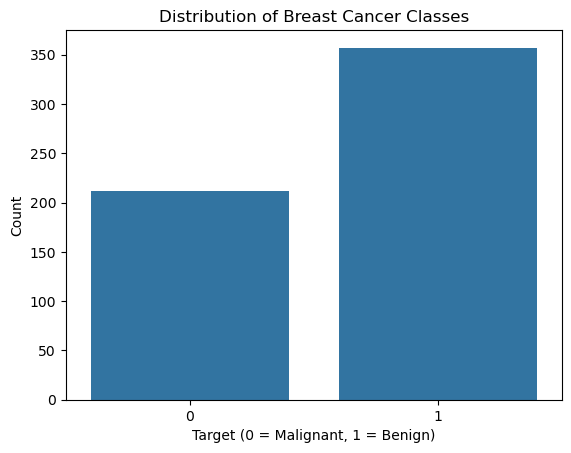

In [10]:
sns.countplot(data=cancer_df, x='target')
plt.title('Distribution of Breast Cancer Classes')
plt.xlabel('Target (0 = Malignant, 1 = Benign)')
plt.ylabel('Count')
plt.show()

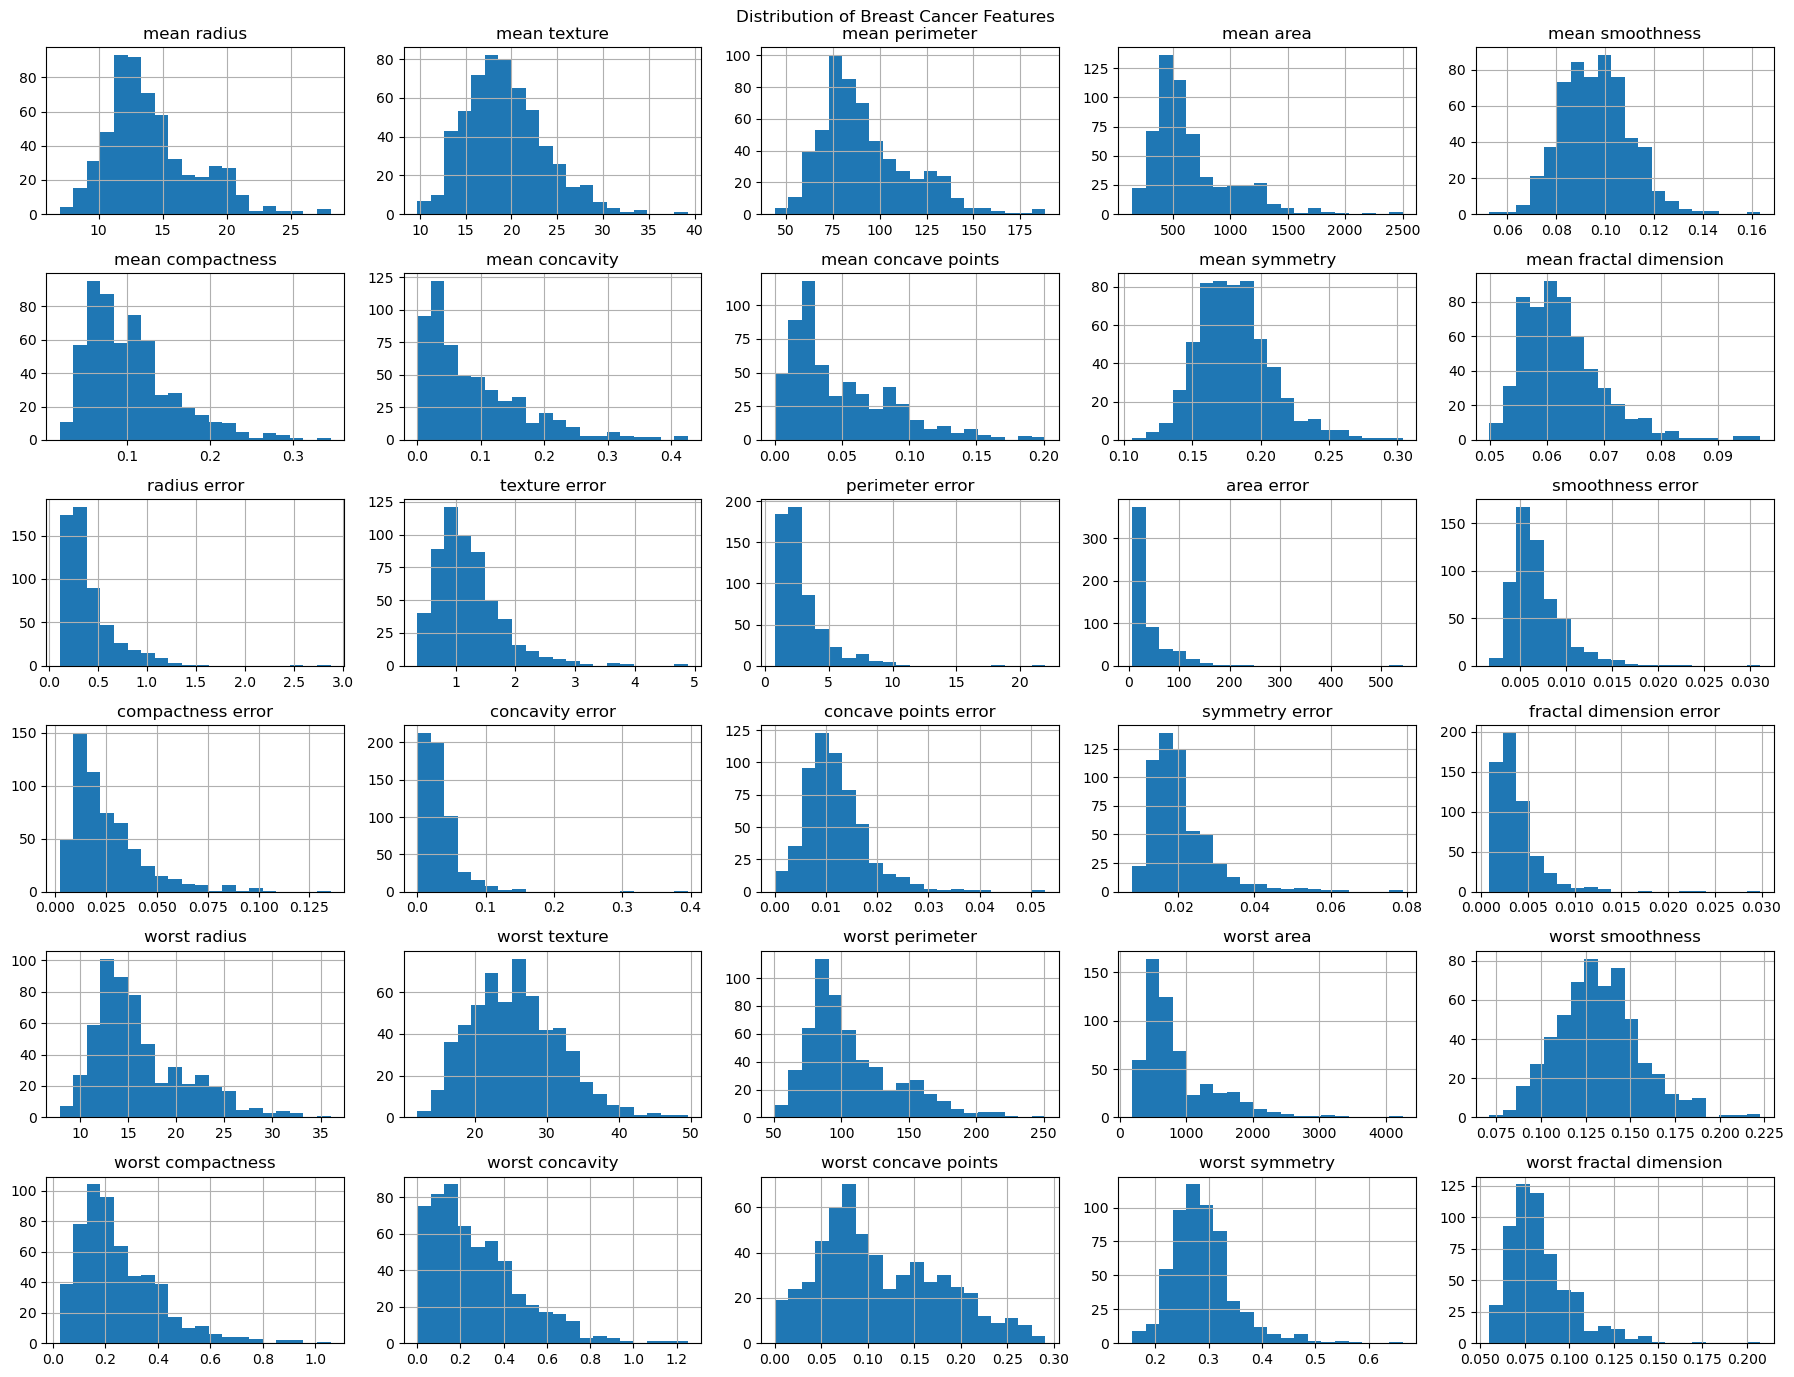

In [11]:
# feature distributions
cancer_df.drop(columns='target').hist(figsize=(18, 14), bins=20)
plt.suptitle('Distribution of Breast Cancer Features')
plt.tight_layout()
plt.show()

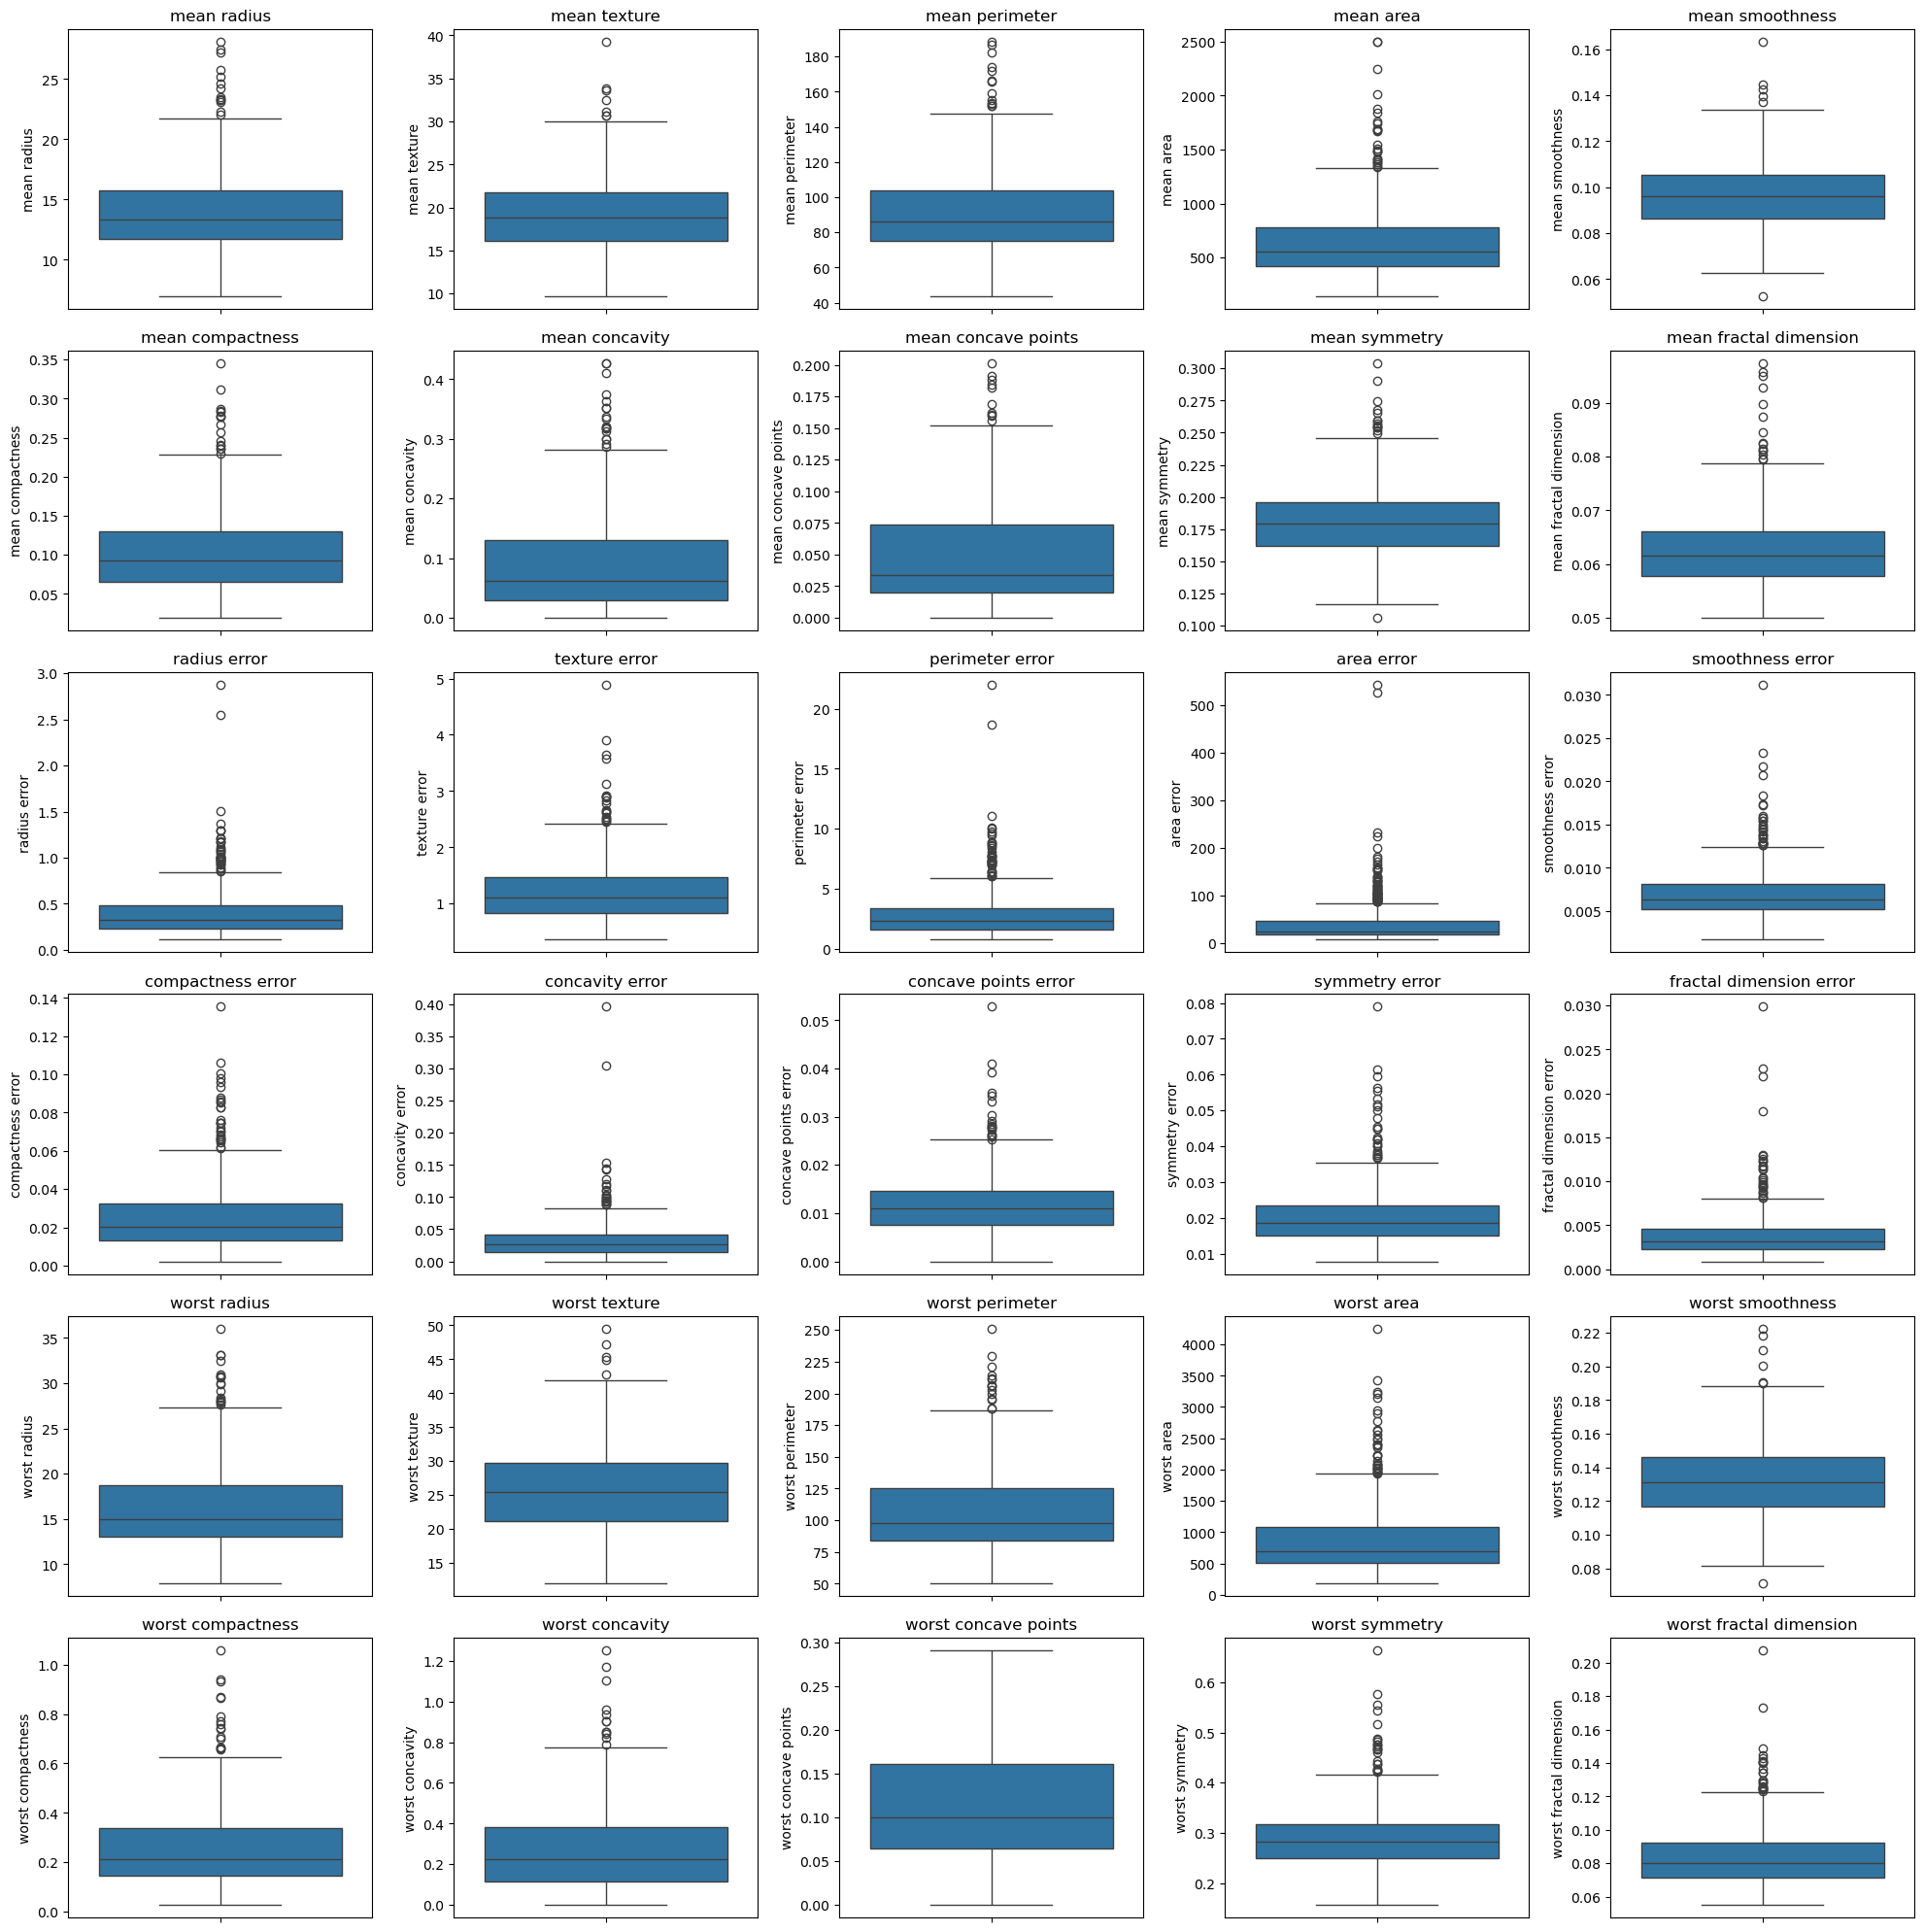

In [12]:
# outlier detection
features = cancer_df.drop(columns='target').columns
n_cols = 5
n_rows = (len(features) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 20))
axes = axes.flatten()

for i, column in enumerate(features):
    sns.boxplot(data=cancer_df, y=column, ax=axes[i])
    axes[i].set_title(column)

for j in range(len(features), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

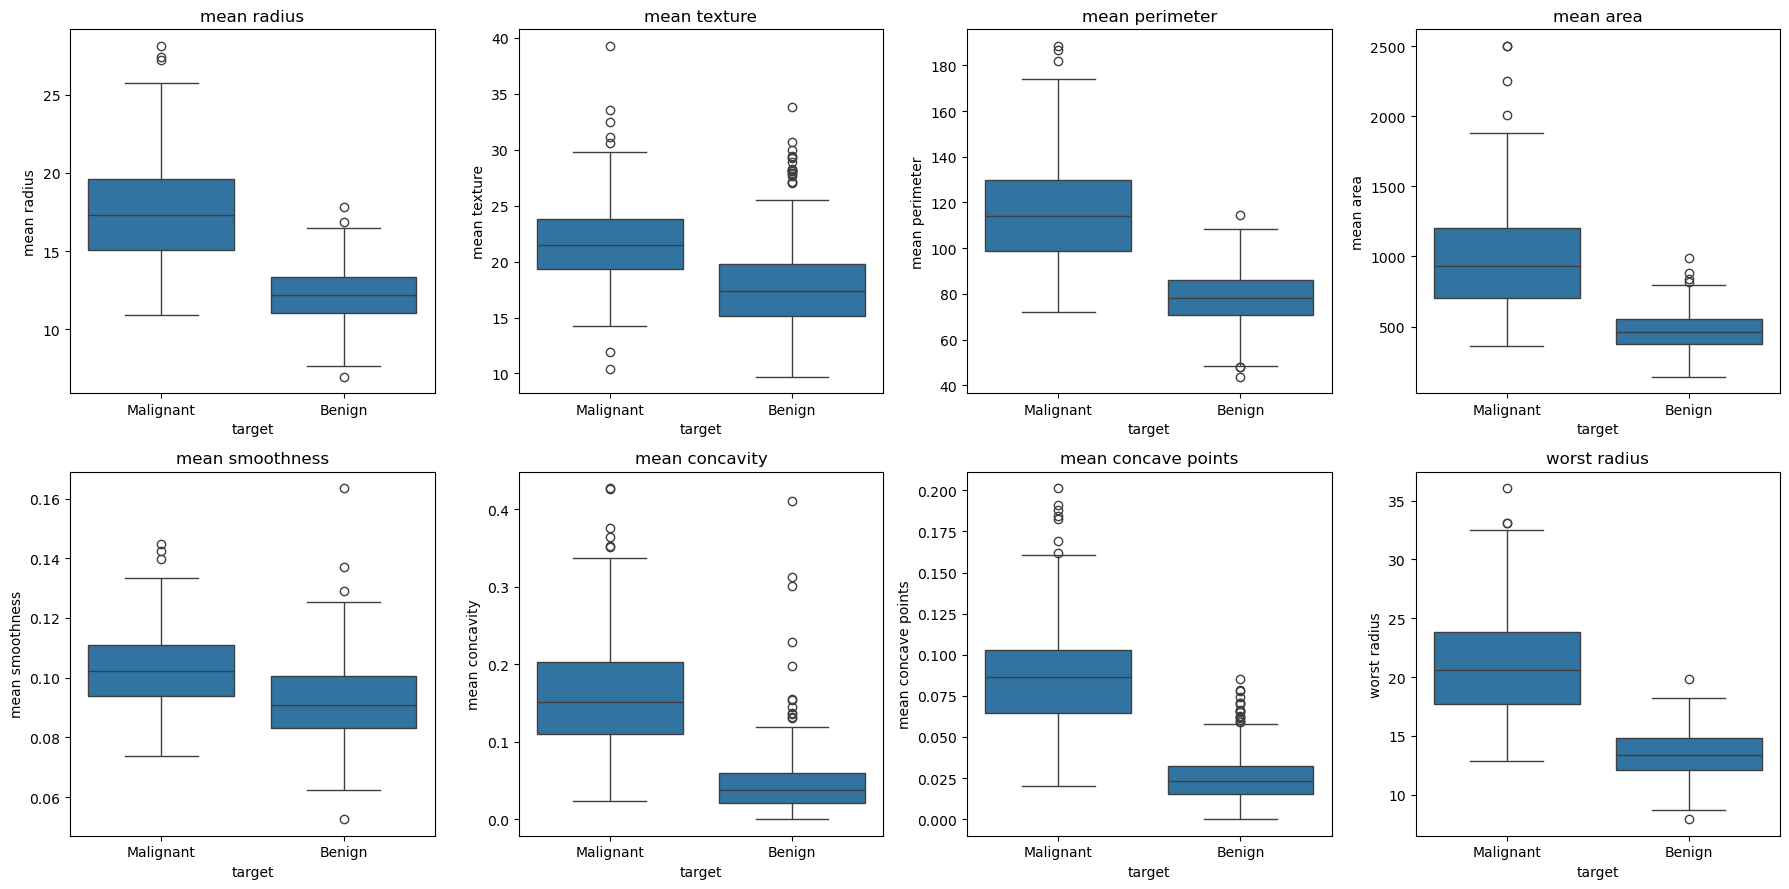

In [14]:
# feature rlship with target
selected_features = [
    'mean radius',
    'mean texture',
    'mean perimeter',
    'mean area',
    'mean smoothness',
    'mean concavity',
    'mean concave points',
    'worst radius'
]

fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.flatten()

for i, column in enumerate(selected_features):
    sns.boxplot(data=cancer_df, x='target', y=column, ax=axes[i])
    axes[i].set_title(column)
    axes[i].set_xticks([0, 1], ['Malignant', 'Benign'])

plt.tight_layout()
plt.show()

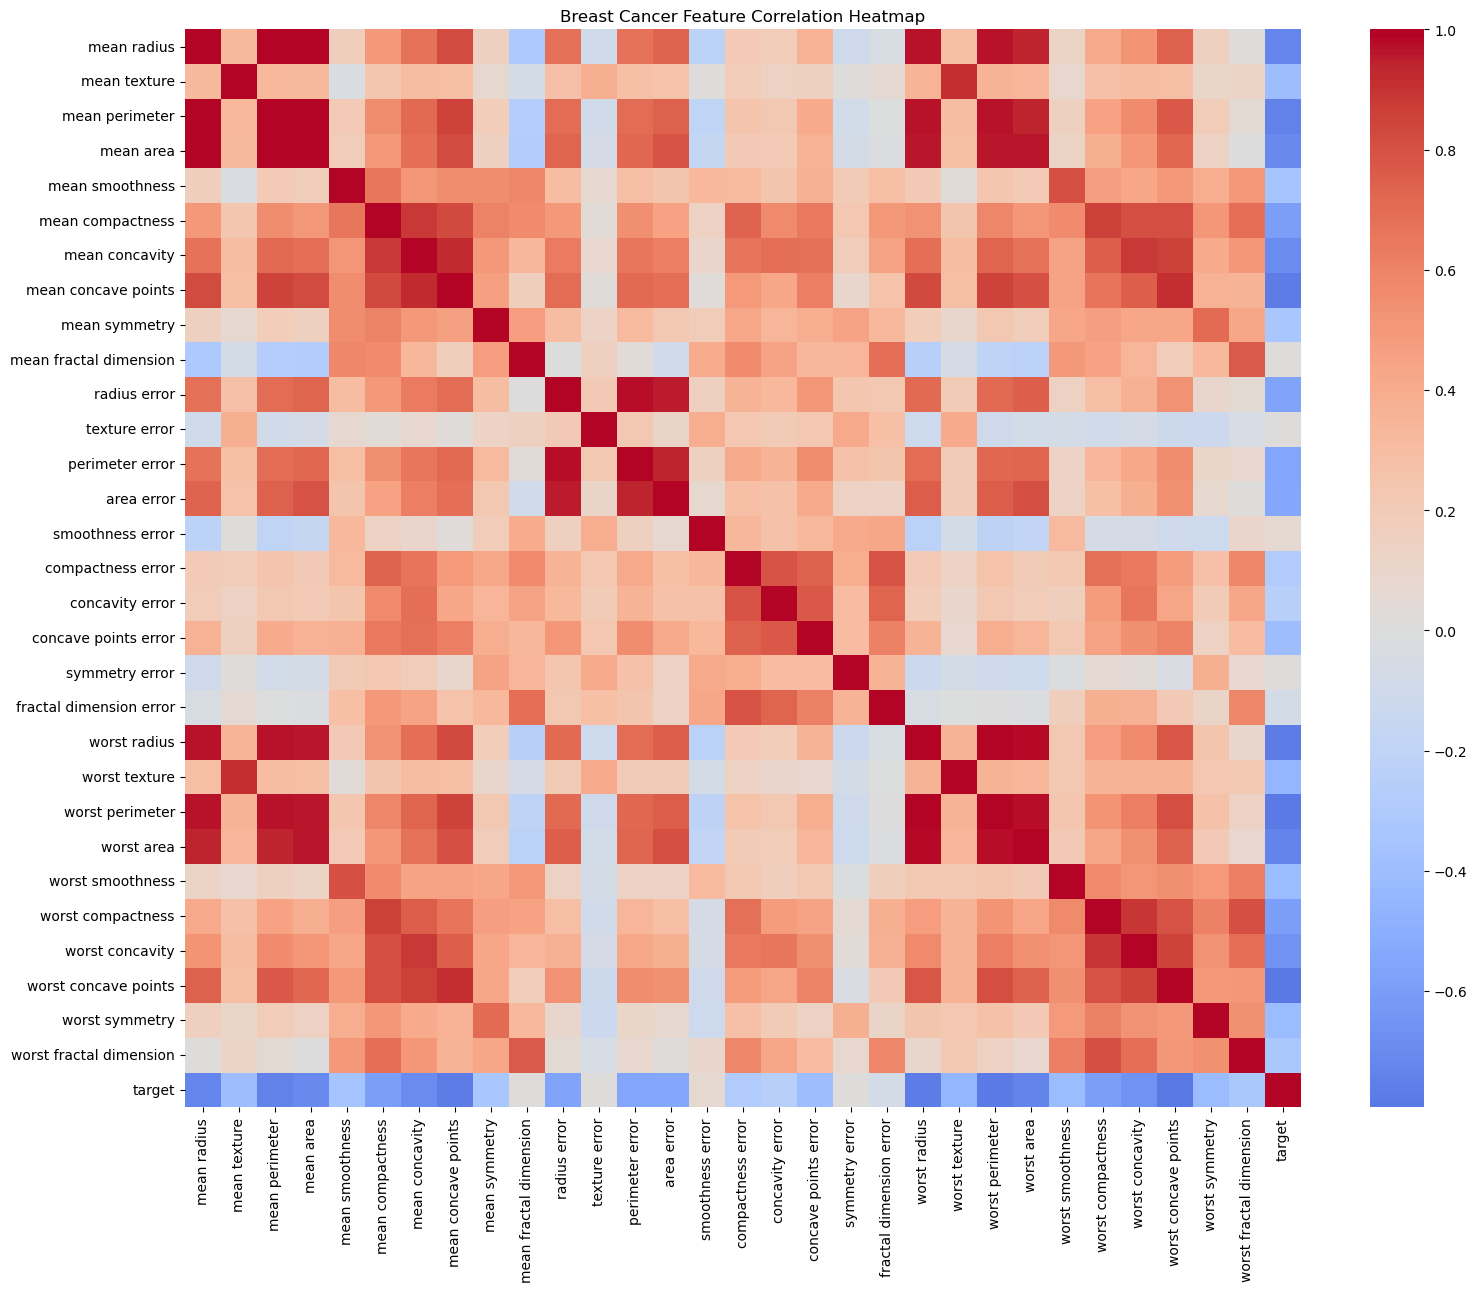

In [15]:
# Correlation
plt.figure(figsize=(18, 14))
sns.heatmap(cancer_df.corr(),cmap='coolwarm',center=0)
plt.title('Breast Cancer Feature Correlation Heatmap')
plt.show()

In [16]:
# preprocessing
# feature and target
X = cancer_df.drop(columns='target')
y = cancer_df['target']

In [18]:
# split dataset
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.2,random_state=42,stratify=y)
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (455, 30)
X_test: (114, 30)
y_train: (455,)
y_test: (114,)


In [19]:
# Model
tree_model = DecisionTreeClassifier(criterion='gini',random_state=42)

tree_model.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [20]:
# predictions
y_train_pred = tree_model.predict(X_train)
y_test_pred = tree_model.predict(X_test)

y_test_proba = tree_model.predict_proba(X_test)[:, 1]

In [21]:
# Evaluation Metrics
accuracy = accuracy_score(y_test, y_test_pred)
precision = precision_score(y_test, y_test_pred)
recall = recall_score(y_test, y_test_pred)
f1 = f1_score(y_test, y_test_pred)
roc_auc = roc_auc_score(y_test, y_test_proba)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

Accuracy:  0.9123
Precision: 0.9559
Recall:    0.9028
F1 Score:  0.9286
ROC-AUC:   0.9157


In [22]:
# classification report
print(classification_report(y_test,y_test_pred,target_names=cancer.target_names))

              precision    recall  f1-score   support

   malignant       0.85      0.93      0.89        42
      benign       0.96      0.90      0.93        72

    accuracy                           0.91       114
   macro avg       0.90      0.92      0.91       114
weighted avg       0.92      0.91      0.91       114



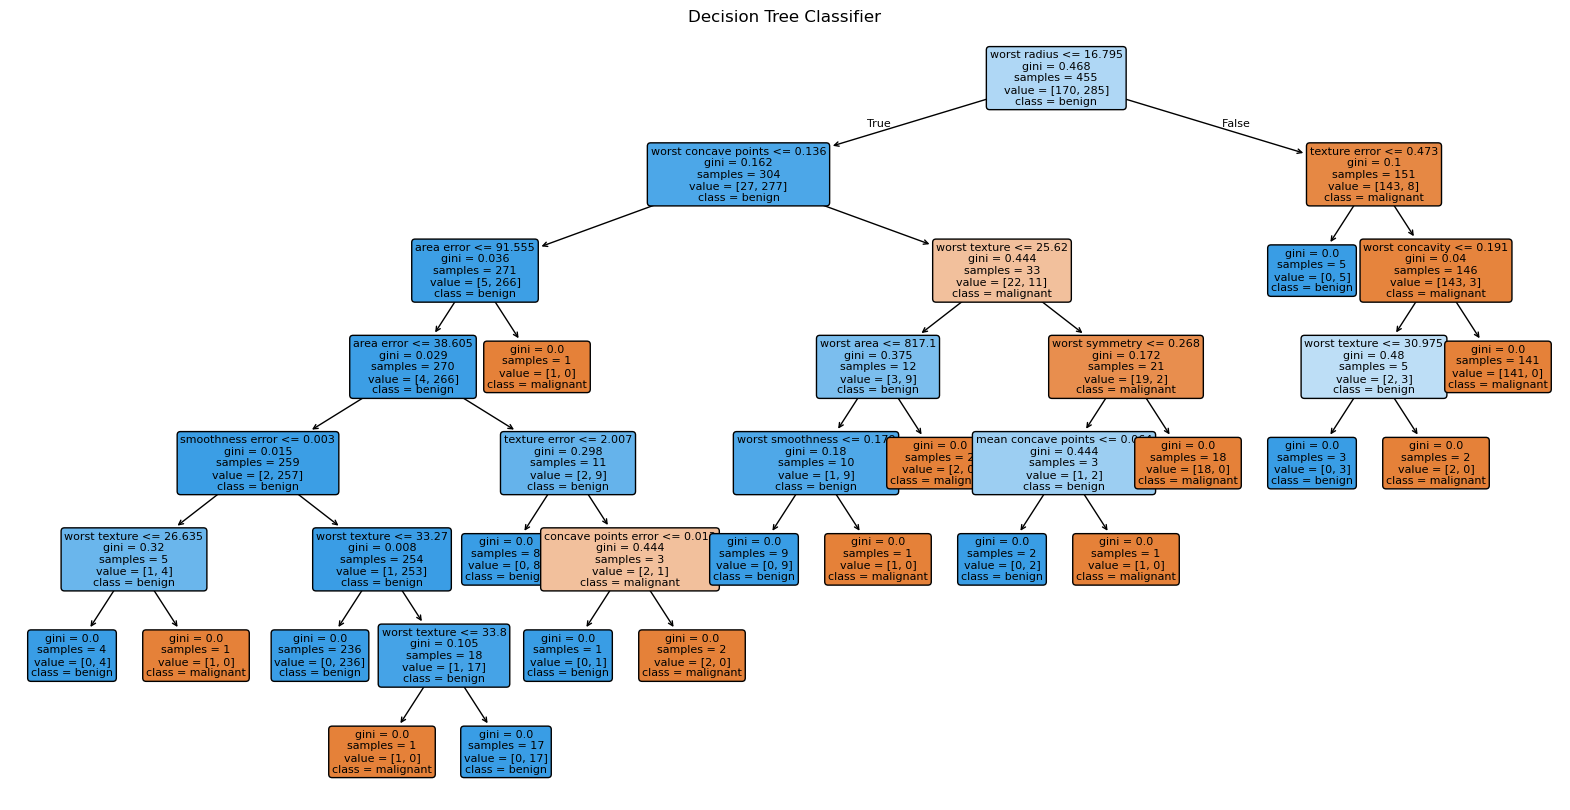

In [23]:
# confusion matrix
plt.figure(figsize=(20, 10))

plot_tree(tree_model,feature_names=X.columns,class_names=cancer.target_names,filled=True,rounded=True,fontsize=8)

plt.title('Decision Tree Classifier')
plt.show()